In [32]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uwinezagloria/country-schools/Country Schools.csv


# Lab 2: Anomaly Detection and Cluster Analysis — Country Schools Dataset
Dataset: number of schools per county, schools with digital devices installed, schools pending,
percentage installed, Learner Digital Devices (LDDs) and Teacher Digital Devices (TDDs).

In [33]:
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")

DATA_PATH = glob.glob("/kaggle/input/**/*.csv", recursive=True)[0]
print("Loading:", DATA_PATH)

df_raw = pd.read_csv(DATA_PATH)
print("Shape:", df_raw.shape)
display(df_raw.tail(5))

Loading: /kaggle/input/datasets/uwinezagloria/country-schools/Country Schools.csv
Shape: (50, 8)


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
45,EMBU,381.0,248.0,133.0,65.09%,8438.0,496.0,46
46,SAMBURU,146.0,49.0,97.0,33.56%,2891.0,98.0,47
47,TOTAL,21729.0,14629.0,7100.0,67.32%,723618.0,29258.0,48
48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,49
49,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50


In [34]:
print("Data types:")
print(df_raw.dtypes)
print("\nMissing values per column:")
print(df_raw.isna().sum())
print("\nDuplicate rows:", df_raw.duplicated().sum())

Data types:
SNO                       object
TOTALSCHOOLS             float64
TotalSchoolsInstalled    float64
SchoolsPending           float64
PercentageInstalled       object
InstalledLDDs            float64
InstalledTDDs            float64
FID                        int64
dtype: object

Missing values per column:
SNO                      2
TOTALSCHOOLS             2
TotalSchoolsInstalled    2
SchoolsPending           2
PercentageInstalled      2
InstalledLDDs            2
InstalledTDDs            2
FID                      0
dtype: int64

Duplicate rows: 0


In [35]:
df = df_raw.copy()

# 1. Rename columns to clearer names
df = df.rename(columns={"SNO": "County", "TOTALSCHOOLS": "TotalSchools"})

# 2. Remove empty rows (no county name)
df = df.dropna(subset=["County"])

# 3. Remove the 'TOTAL' summary row (it is not a county and would be an artificial outlier)
total_row = df[df["County"].str.strip().str.upper() == "TOTAL"]
df = df[df["County"].str.strip().str.upper() != "TOTAL"].copy()

# 4. Tidy county names (remove extra spaces, consistent capitalisation)
df["County"] = df["County"].str.strip().str.title()

# 5. Convert '10.34%' text to the number 10.34
df["PercentageInstalled"] = df["PercentageInstalled"].str.replace("%", "", regex=False).astype(float)

# 6. Drop FID (it is only a row ID, not a measurement)
df = df.drop(columns=["FID"])

# 7. Fix data types
num_cols = ["TotalSchools", "TotalSchoolsInstalled", "SchoolsPending", "InstalledLDDs", "InstalledTDDs"]
df[num_cols] = df[num_cols].astype(int)
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after cleaning:", df.shape)
print("Missing values left:", df.isna().sum().sum())
display(df.head())

Shape after cleaning: (47, 7)
Missing values left: 0


,County,TotalSchools,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs
0,Turkana,358,37,321,10.34,3744,74
1,Homa Bay,875,552,323,63.09,22982,1104
2,West Pokot,498,242,256,48.59,15114,484
3,Kitui,1238,1200,38,96.93,42162,2400
4,Tana River,159,143,16,89.94,7415,286


In [36]:
# Installed + Pending should equal Total for every county
print("Installed + Pending == Total:",
      (df["TotalSchoolsInstalled"] + df["SchoolsPending"] == df["TotalSchools"]).all())

# Teacher devices = 2 per installed school?
print("TDDs == 2 x installed schools:",
      (df["InstalledTDDs"] == 2 * df["TotalSchoolsInstalled"]).all())

# Do county sums match the TOTAL row we removed?
print("\nSum of counties:\n", df[num_cols].sum())
print("\nTOTAL row in file:\n", total_row[["TotalSchools", "TotalSchoolsInstalled",
                                          "SchoolsPending", "InstalledLDDs", "InstalledTDDs"]])

Installed + Pending == Total: True
TDDs == 2 x installed schools: True

Sum of counties:
 TotalSchools              21729
TotalSchoolsInstalled     14629
SchoolsPending             7100
InstalledLDDs            723618
InstalledTDDs             29258
dtype: int64

TOTAL row in file:
     TotalSchools  TotalSchoolsInstalled  SchoolsPending  InstalledLDDs  \
47       21729.0                14629.0          7100.0       723618.0   

    InstalledTDDs  
47        29258.0  


,count,mean,std,min,25%,50%,75%,max
TotalSchools,47.0,462.32,254.20,93.00,251.50,413.0,633.50,1238.00
TotalSchoolsInstalled,47.0,311.26,229.00,8.00,156.50,307.0,408.50,1200.00
SchoolsPending,47.0,151.06,113.80,4.00,52.50,130.0,243.00,448.00
PercentageInstalled,47.0,63.92,25.85,4.55,50.30,65.0,84.94,96.93
InstalledLDDs,47.0,15396.13,11479.58,606.00,6166.00,13507.0,22838.50,44338.00
InstalledTDDs,47.0,622.51,458.00,16.00,313.00,614.0,817.00,2400.00
LDDsPerSchool,47.0,53.00,19.54,25.70,38.25,47.7,61.50,116.20


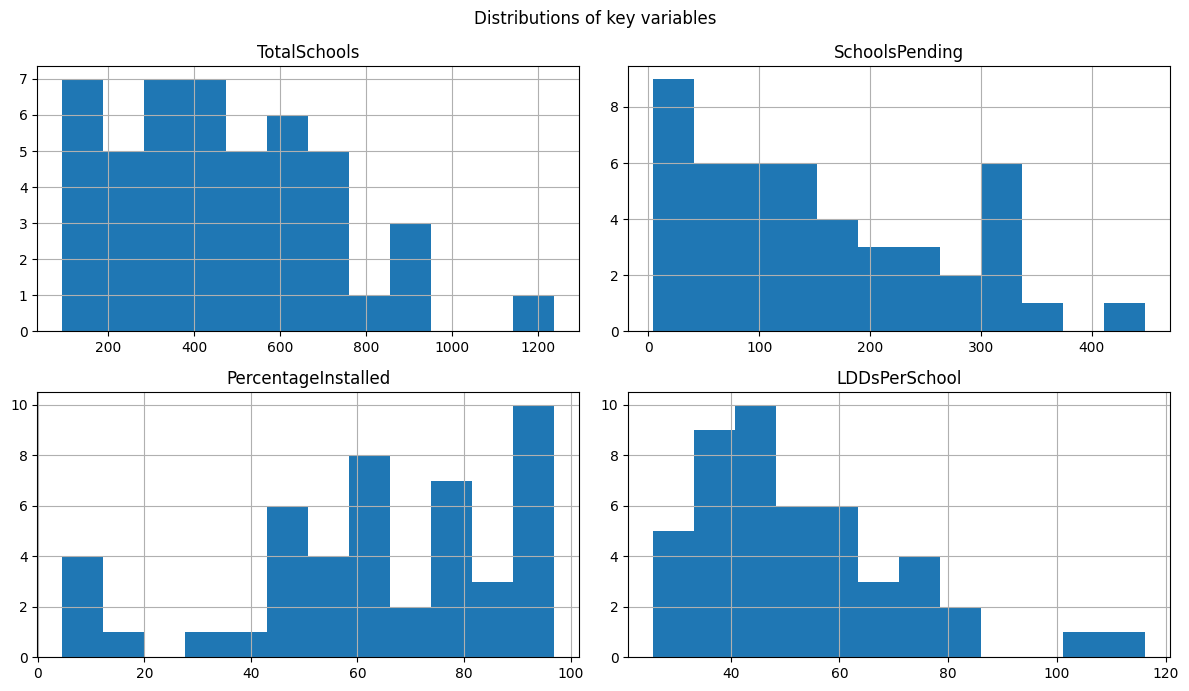

In [37]:
# Learner devices per installed school (fair comparison between big and small counties)
df["LDDsPerSchool"] = (df["InstalledLDDs"] / df["TotalSchoolsInstalled"]).round(1)

display(df.describe().T.round(2))

df[["TotalSchools", "SchoolsPending", "PercentageInstalled", "LDDsPerSchool"]].hist(
    bins=12, figsize=(12, 7))
plt.suptitle("Distributions of key variables")
plt.tight_layout()
plt.show()

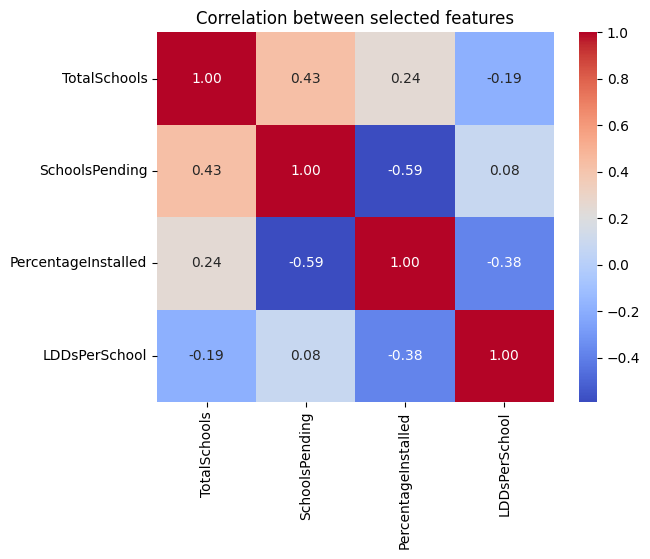

In [38]:
# TDDs is exactly 2 x installed schools, and Installed = Total - Pending,
# so we keep non-redundant features only.
features = ["TotalSchools", "SchoolsPending", "PercentageInstalled", "LDDsPerSchool"]

scaler = StandardScaler()
X = scaler.fit_transform(df[features])
X_scaled = pd.DataFrame(X, columns=features, index=df.index)

sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation between selected features")
plt.show()

### Preprocessing summary
- Removed 2 empty rows and the 'TOTAL' summary row (it is an aggregate, not a county).
- Converted PercentageInstalled from text ("10.34%") to numeric.
- Dropped FID (identifier only) and cleaned county names.
- Verified consistency: Installed + Pending = Total; TDDs = 2 per installed school.
- Created LDDsPerSchool to compare counties of different sizes fairly.
- Dropped redundant columns and standardised features (mean 0, std 1), because
  distance-based methods (K-Means, LOF) are sensitive to scale.

## 2. Anomaly Detection
Goal: identify counties whose device-installation profile is unusual compared with other counties.
We apply two statistical methods (Z-score, IQR) and two machine-learning methods
(Isolation Forest, Local Outlier Factor), then compare results.

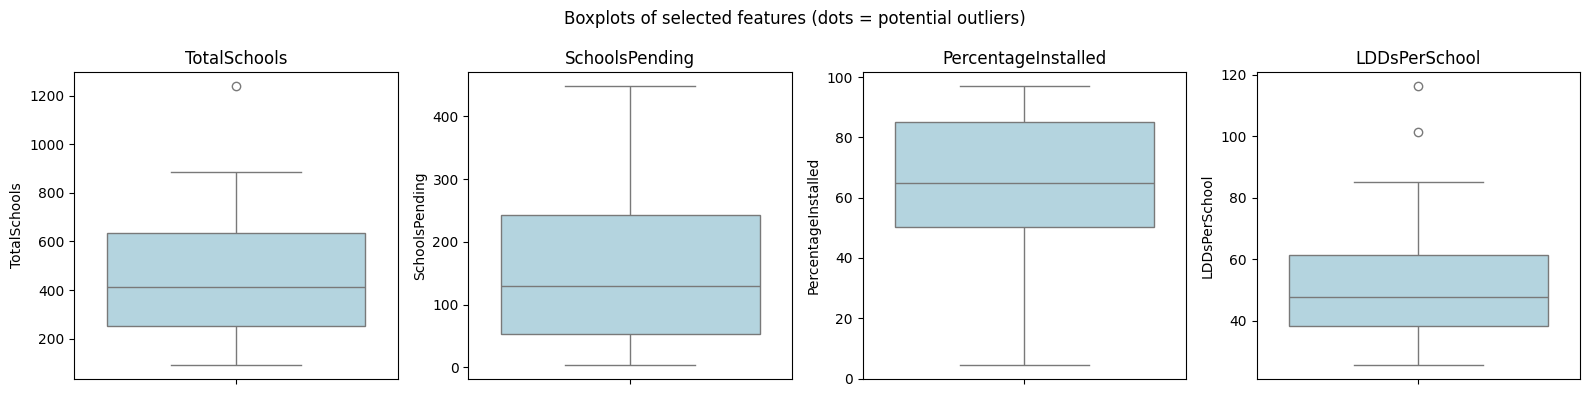

In [39]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, features):
    sns.boxplot(y=df[col], ax=ax, color="lightblue")
    ax.set_title(col)
plt.suptitle("Boxplots of selected features (dots = potential outliers)")
plt.tight_layout()
plt.show()

In [40]:
# |z| > 2.5 means more than 2.5 standard deviations from the mean
z_threshold = 2.5
df["Zscore_max"] = X_scaled.abs().max(axis=1).round(2)
df["Outlier_Z"] = (df["Zscore_max"] > z_threshold).astype(int)

print("Z-score outliers (|z| > 2.5 on at least one feature):")
display(df[df["Outlier_Z"] == 1][["County"] + features + ["Zscore_max"]])

Z-score outliers (|z| > 2.5 on at least one feature):


,County,TotalSchools,SchoolsPending,PercentageInstalled,LDDsPerSchool,Zscore_max
3,Kitui,1238,38,96.93,35.1,3.08
30,Mandera,198,189,4.55,116.2,3.27
39,Machakos,837,448,46.48,34.4,2.64


In [41]:
df["Outlier_IQR"] = 0
for col in features:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    mask = (df[col] < lower) | (df[col] > upper)
    df.loc[mask, "Outlier_IQR"] = 1
    print(f"{col}: bounds [{lower:.1f}, {upper:.1f}] -> outliers: {df.loc[mask, 'County'].tolist()}")

TotalSchools: bounds [-321.5, 1206.5] -> outliers: ['Kitui']
SchoolsPending: bounds [-233.2, 528.8] -> outliers: []
PercentageInstalled: bounds [-1.6, 136.9] -> outliers: []
LDDsPerSchool: bounds [3.4, 96.4] -> outliers: ['Turkana', 'Mandera']


In [42]:
# contamination=0.1 assumes about 10% of counties (~5) are anomalous
iso = IsolationForest(n_estimators=200, contamination=0.1, random_state=42)
df["Outlier_IF"] = (iso.fit_predict(X_scaled) == -1).astype(int)
df["IF_score"] = iso.decision_function(X_scaled).round(3)   # lower = more anomalous

print("Isolation Forest anomalies:")
display(df[df["Outlier_IF"] == 1][["County"] + features + ["IF_score"]].sort_values("IF_score"))

Isolation Forest anomalies:


,County,TotalSchools,SchoolsPending,PercentageInstalled,LDDsPerSchool,IF_score
0,Turkana,358,321,10.34,101.2,-0.089
30,Mandera,198,189,4.55,116.2,-0.084
39,Machakos,837,448,46.48,34.4,-0.060
3,Kitui,1238,38,96.93,35.1,-0.044
36,Wajir,211,200,5.21,77.7,-0.002


In [43]:
lof = LocalOutlierFactor(n_neighbors=10, contamination=0.1)
df["Outlier_LOF"] = (lof.fit_predict(X_scaled) == -1).astype(int)
df["LOF_score"] = (-lof.negative_outlier_factor_).round(2)   # >1 = less dense than neighbours

print("LOF anomalies:")
display(df[df["Outlier_LOF"] == 1][["County"] + features + ["LOF_score"]]
        .sort_values("LOF_score", ascending=False))

LOF anomalies:


,County,TotalSchools,SchoolsPending,PercentageInstalled,LDDsPerSchool,LOF_score
3,Kitui,1238,38,96.93,35.1,1.98
30,Mandera,198,189,4.55,116.2,1.68
0,Turkana,358,321,10.34,101.2,1.51
38,Marsabit,138,130,5.80,75.8,1.38
36,Wajir,211,200,5.21,77.7,1.37


In [44]:
df["Votes"] = df[["Outlier_Z", "Outlier_IQR", "Outlier_IF", "Outlier_LOF"]].sum(axis=1)

comparison = df[df["Votes"] > 0][["County", "Outlier_Z", "Outlier_IQR", "Outlier_IF",
                                  "Outlier_LOF", "Votes"]].sort_values("Votes", ascending=False)
display(comparison)

,County,Outlier_Z,Outlier_IQR,Outlier_IF,Outlier_LOF,Votes
3,Kitui,1,1,1,1,4
30,Mandera,1,1,1,1,4
0,Turkana,0,1,1,1,3
36,Wajir,0,0,1,1,2
39,Machakos,1,0,1,0,2
38,Marsabit,0,0,0,1,1


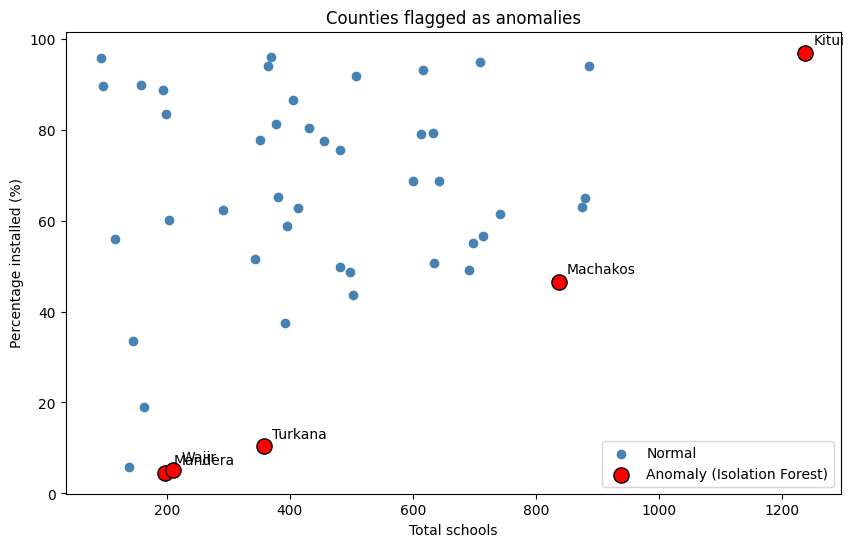

In [45]:
plt.figure(figsize=(10, 6))
normal = df[df["Outlier_IF"] == 0]
anom = df[df["Outlier_IF"] == 1]
plt.scatter(normal["TotalSchools"], normal["PercentageInstalled"], c="steelblue", label="Normal")
plt.scatter(anom["TotalSchools"], anom["PercentageInstalled"], c="red", s=120,
            edgecolor="black", label="Anomaly (Isolation Forest)")
for _, r in df[df["Votes"] >= 2].iterrows():
    plt.annotate(r["County"], (r["TotalSchools"], r["PercentageInstalled"]),
                 xytext=(6, 6), textcoords="offset points")
plt.xlabel("Total schools")
plt.ylabel("Percentage installed (%)")
plt.title("Counties flagged as anomalies")
plt.legend()
plt.show()

### Interpretation of anomaly detection
- **Kitui** is the most consistent anomaly: it is by far the largest county (1,238 schools,
  ~2.7× the average) yet has one of the highest installation rates (96.9%). It is a
  "positive" anomaly — an outstanding performer in size and coverage.
- **Mandera, Wajir, Turkana and Marsabit** are anomalies in the opposite direction: very low
  installation rates (4.6%–10.3%) and an unusually high number of learner devices per installed
  school (Mandera ≈116, Turkana ≈101, against an average of ≈53). Few schools received devices,
  but those schools received many. These are mostly arid/remote northern counties, which suggests
  access, infrastructure or security challenges slowed the rollout.
- **Machakos** is flagged by Z-score and Isolation Forest because it has the highest number of
  pending schools (448).
- Statistical methods (Z-score, IQR) look at **one feature at a time**, so they found fewer
  anomalies. Isolation Forest and LOF consider **all features together**, so they detected
  counties that are unusual in their combination of values (e.g. Wajir, Marsabit).
- Counties flagged by several methods (high "Votes") are the most reliable anomalies.
- These anomalies are **real observations, not data errors** (the consistency checks passed),
  so they were kept in the dataset. They should be investigated, not deleted.

## 3. Cluster Analysis
Goal: group counties with similar installation profiles. We use K-Means (main method) and
Hierarchical (Agglomerative) clustering for comparison. The number of clusters is chosen with the
Elbow method and the Silhouette score.

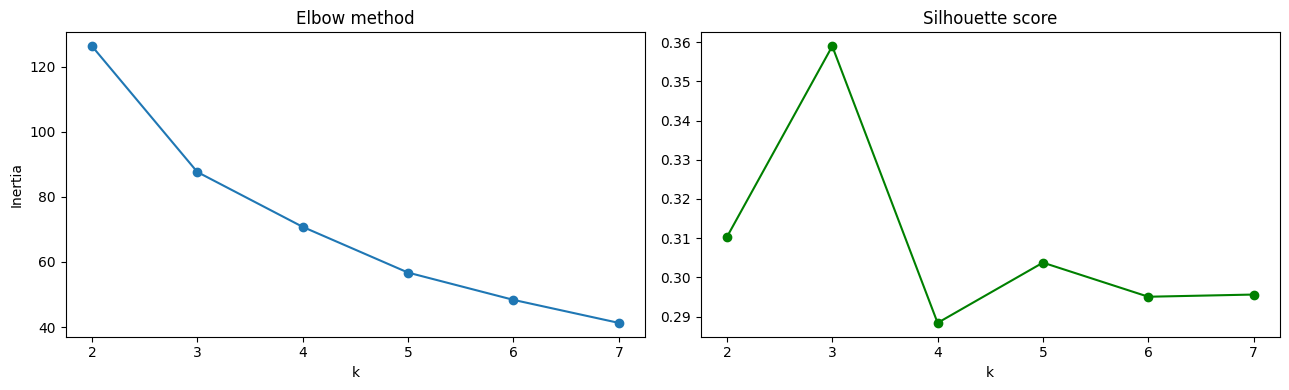

,k,Inertia,Silhouette
0,2,126.3,0.310
1,3,87.6,0.359
2,4,70.8,0.288
3,5,56.7,0.304
4,6,48.3,0.295
5,7,41.3,0.296


In [46]:
inertias, silhouettes = [], []
K = range(2, 8)
for k in K:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(K, inertias, "o-"); ax[0].set_title("Elbow method"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia")
ax[1].plot(K, silhouettes, "o-", color="green"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

display(pd.DataFrame({"k": list(K), "Inertia": np.round(inertias, 1),
                      "Silhouette": np.round(silhouettes, 3)}))

In [47]:
k_best = 3
kmeans = KMeans(n_clusters=k_best, n_init=10, random_state=42)
df["Cluster"] = kmeans.fit_predict(X_scaled)
print("Silhouette score (k=3):", round(silhouette_score(X_scaled, df["Cluster"]), 3))

# Cluster profiles: average value of each feature per cluster
profile = df.groupby("Cluster")[features].mean().round(1)
profile["NumCounties"] = df["Cluster"].value_counts().sort_index()
display(profile)

for c, group in df.groupby("Cluster"):
    print(f"\nCluster {c}: {group['County'].tolist()}")

Silhouette score (k=3): 0.359


,TotalSchools,SchoolsPending,PercentageInstalled,LDDsPerSchool,NumCounties
Cluster,,,,,
0,202.3,178.2,13.1,80.1,6
1,419.5,72.7,80.0,48.2,27
2,656.4,290.5,54.6,50.7,14



Cluster 0: ['Turkana', 'Garissa', 'Mandera', 'Wajir', 'Marsabit', 'Samburu']

Cluster 1: ['Kitui', 'Tana River', 'Taita Taveta', 'Uasin Gishu', 'Vihiga', 'Nyamira', 'Narok', 'Nandi', 'Mombasa', 'Makueni', 'Lamu', 'Kisumu', 'Bomet', 'Kilifi', 'Busia', 'Elgeyo', 'Trans Nzoia', 'Kwale', 'Laikipia', 'Kirinyaga', 'Isiolo', "Murang'A", 'Nyandarua', 'Nairobi', 'Tharaka Nithi', 'Kajiado', 'Embu']

Cluster 2: ['Homa Bay', 'West Pokot', 'Migori', 'Kisii', 'Kakamega', 'Bungoma', 'Siaya', 'Kericho', 'Meru', 'Kiambu', 'Nyeri', 'Machakos', 'Nakuru', 'Baringo']


Variance explained by PC1 + PC2: 79.0 %


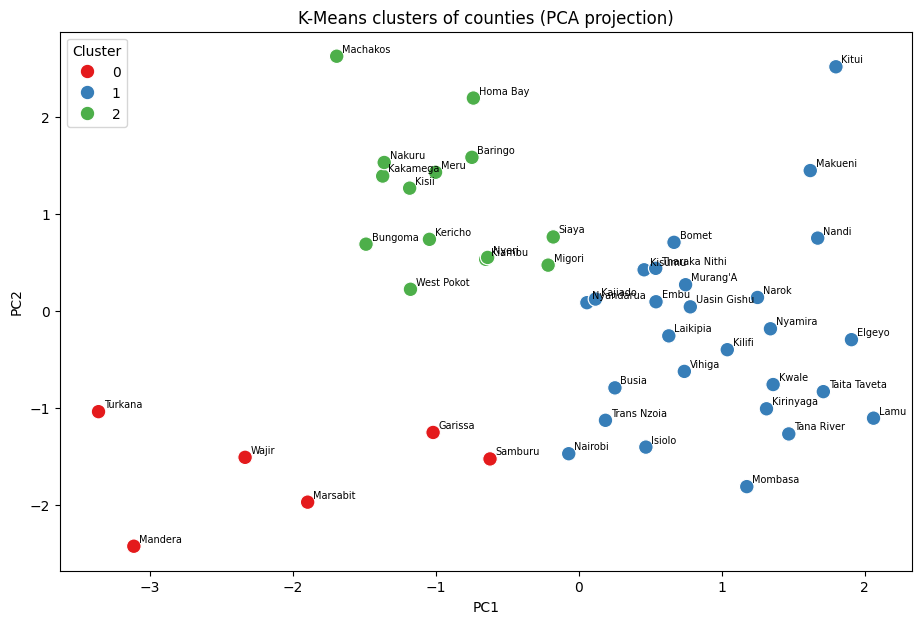

In [48]:
pca = PCA(n_components=2)
pcs = pca.fit_transform(X_scaled)
df["PC1"], df["PC2"] = pcs[:, 0], pcs[:, 1]
print("Variance explained by PC1 + PC2:", round(pca.explained_variance_ratio_.sum() * 100, 1), "%")

plt.figure(figsize=(11, 7))
sns.scatterplot(data=df, x="PC1", y="PC2", hue="Cluster", palette="Set1", s=110)
for _, r in df.iterrows():
    plt.annotate(r["County"], (r["PC1"], r["PC2"]), fontsize=7, xytext=(4, 3), textcoords="offset points")
plt.title("K-Means clusters of counties (PCA projection)")
plt.show()

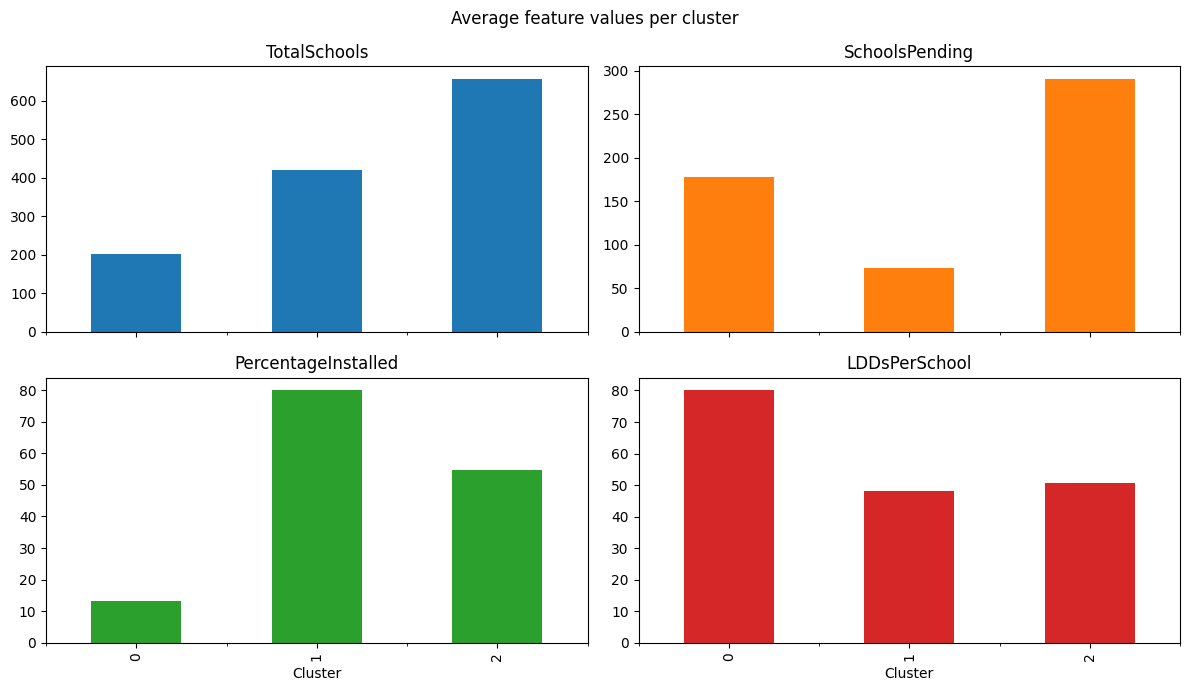

In [49]:
profile[features].plot(kind="bar", subplots=True, layout=(2, 2), figsize=(12, 7), legend=False)
plt.suptitle("Average feature values per cluster")
plt.tight_layout(); plt.show()

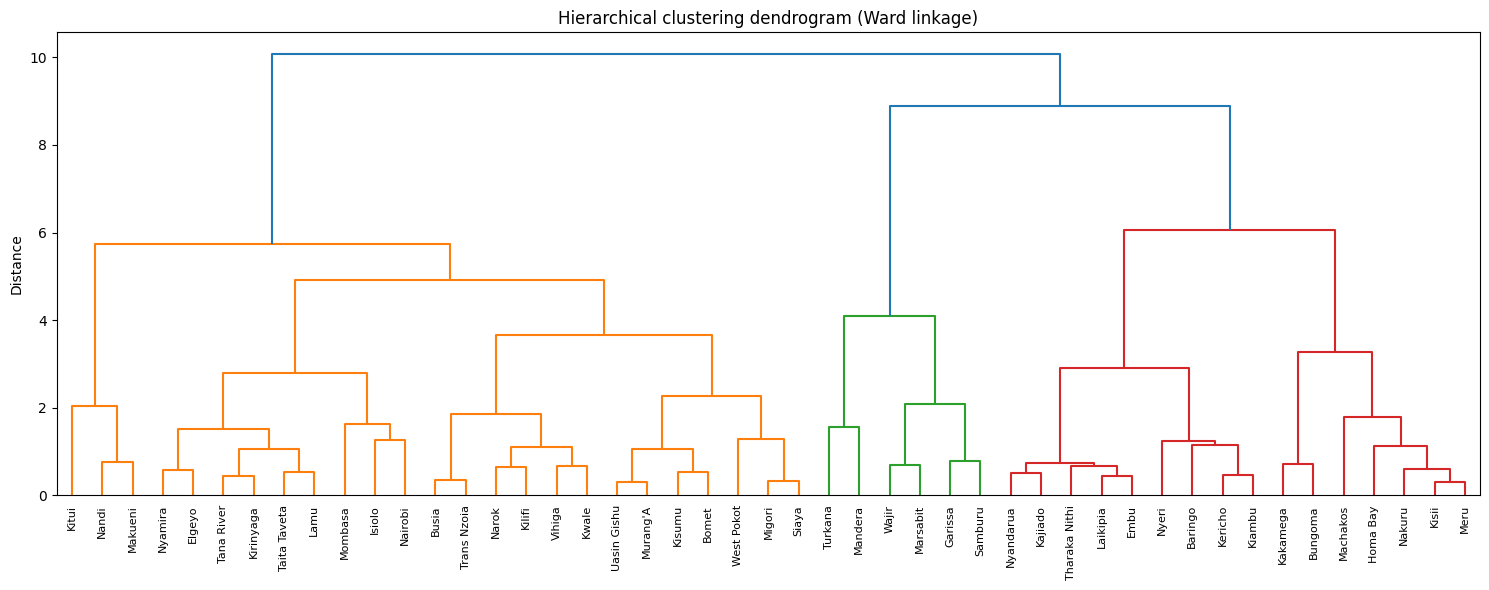

Hierarchical silhouette: 0.296
Agreement with K-Means (Adjusted Rand Index): 0.496


Cluster_HC,0,1,2
Cluster,,,
0,0,0,6
1,5,22,0
2,11,3,0


In [50]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.metrics import adjusted_rand_score

plt.figure(figsize=(15, 6))
dendrogram(linkage(X_scaled, method="ward"), labels=df["County"].tolist(), leaf_rotation=90)
plt.title("Hierarchical clustering dendrogram (Ward linkage)")
plt.ylabel("Distance")
plt.tight_layout(); plt.show()

agg = AgglomerativeClustering(n_clusters=3, linkage="ward")
df["Cluster_HC"] = agg.fit_predict(X_scaled)
print("Hierarchical silhouette:", round(silhouette_score(X_scaled, df["Cluster_HC"]), 3))
print("Agreement with K-Means (Adjusted Rand Index):",
      round(adjusted_rand_score(df["Cluster"], df["Cluster_HC"]), 3))
display(pd.crosstab(df["Cluster"], df["Cluster_HC"]))

In [51]:
display(pd.crosstab(df["Cluster"], df["Outlier_IF"], margins=True))

Outlier_IF,0,1,All
Cluster,,,
0,3,3,6
1,26,1,27
2,13,1,14
All,42,5,47


### Interpretation of cluster analysis
- The Elbow curve bends at k=3, and k=3 gives the highest silhouette score (≈0.36),
  so 3 clusters were chosen. A silhouette of 0.36 means the clusters are reasonably,
  but not perfectly, separated, which is expected with only 47 counties.

**Cluster A – "Lagging counties" (6 counties: Turkana, Garissa, Mandera, Wajir, Marsabit, Samburu)**
Small counties (~200 schools), very low installation (~13%), but many devices per installed school (~80).
Mostly arid and remote northern counties. They need the most attention.

**Cluster B – "High performers" (27 counties, e.g. Kitui, Makueni, Nandi, Narok, Lamu, Mombasa)**
Medium-sized (~420 schools) with high installation (~80%) and few pending schools (~73).
The rollout is almost complete.

**Cluster C – "Large counties in progress" (14 counties, e.g. Machakos, Nakuru, Kakamega, Meru, Kiambu)**
Largest counties (~656 schools) with moderate installation (~55%) and the most pending
schools (~290). Most of the remaining national workload is here.

- Hierarchical clustering produced similar groups (ARI ≈ 0.5), which confirms the structure,
  especially the separation of the lagging northern counties.
- The anomalies from Part 2 (Mandera, Wajir, Turkana, Marsabit) all fall in the "lagging"
  cluster, so both analyses tell the same story.

## 4. Conclusion
- Preprocessing removed the summary and empty rows, fixed data types, and confirmed the data is
  internally consistent.
- Anomaly detection identified Kitui as a positive outlier (large and nearly fully installed) and
  northern counties (Mandera, Wajir, Turkana, Marsabit) as negative outliers (very low coverage).
- Cluster analysis grouped the 47 counties into three profiles: lagging, high-performing, and
  large counties still in progress.
- Recommendation: prioritise the lagging cluster for intervention, and focus resources on large
  counties with many pending schools to finish the programme.
- Limitations: small dataset (47 rows), results depend on chosen features and parameters
  (contamination, k), and no information on why installation was delayed.